Initial Exploration & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, norm
from scipy.special import boxcox1p

# Set some display options for pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

# Load the data
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

# Store the test IDs for submission later
test_ID = test['Id']

# Drop the 'Id' column as it's not a predictive feature
train.drop('Id', axis=1, inplace=True)
test.drop('Id', axis=1, inplace=True)

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (1460, 80)
Test shape: (1459, 79)


Target Variable Analysis 

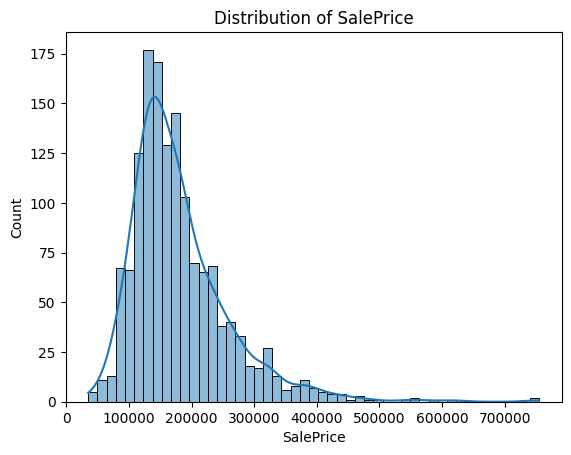

Skewness: 1.8828757597682129


In [2]:
# Visualize the distribution of SalePrice
sns.histplot(train['SalePrice'], kde=True)
plt.title('Distribution of SalePrice')
plt.show()

print(f"Skewness: {train['SalePrice'].skew()}")

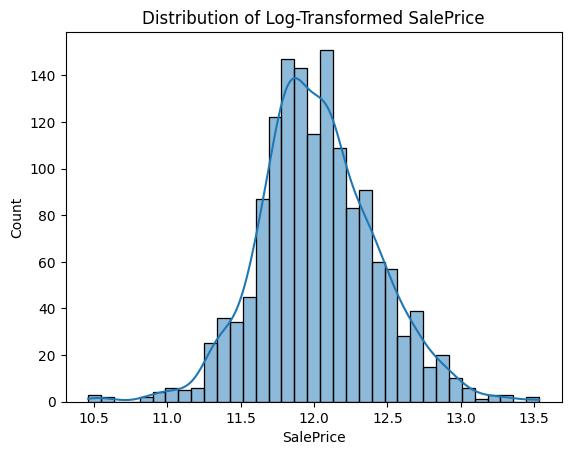

New Skewness: 0.12134661989685333


In [3]:
# Apply log transformation to SalePrice
train['SalePrice'] = np.log1p(train['SalePrice'])

# Visualize the new distribution
sns.histplot(train['SalePrice'], kde=True)
plt.title('Distribution of Log-Transformed SalePrice')
plt.show()

print(f"New Skewness: {train['SalePrice'].skew()}")

Handling Missing Values

In [4]:
# Concatenate train and test data
all_data = pd.concat((train.drop('SalePrice', axis=1), test)).reset_index(drop=True)
print(f"Combined data shape: {all_data.shape}")

# Find missing values and their percentage
missing_values = all_data.isnull().sum().sort_values(ascending=False)
missing_percent = (all_data.isnull().sum() / len(all_data) * 100).sort_values(ascending=False)
missing_data = pd.concat([missing_values, missing_percent], axis=1, keys=['Total', 'Percent'])
print(missing_data[missing_data['Total'] > 0])

Combined data shape: (2919, 79)
              Total    Percent
PoolQC         2909  99.657417
MiscFeature    2814  96.402878
Alley          2721  93.216855
Fence          2348  80.438506
MasVnrType     1766  60.500171
FireplaceQu    1420  48.646797
LotFrontage     486  16.649538
GarageYrBlt     159   5.447071
GarageFinish    159   5.447071
GarageQual      159   5.447071
GarageCond      159   5.447071
GarageType      157   5.378554
BsmtExposure     82   2.809181
BsmtCond         82   2.809181
BsmtQual         81   2.774923
BsmtFinType2     80   2.740665
BsmtFinType1     79   2.706406
MasVnrArea       23   0.787941
MSZoning          4   0.137033
BsmtHalfBath      2   0.068517
Utilities         2   0.068517
BsmtFullBath      2   0.068517
Functional        2   0.068517
TotalBsmtSF       1   0.034258
BsmtFinSF1        1   0.034258
SaleType          1   0.034258
BsmtFinSF2        1   0.034258
GarageCars        1   0.034258
Exterior2nd       1   0.034258
Exterior1st       1   0.034258
GarageA

In [5]:
# Features where NA means "None"
for col in ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']:
    all_data[col] = all_data[col].fillna('None')

In [6]:
# Features where NA means 0
for col in ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']:
    all_data[col] = all_data[col].fillna(0)

In [7]:
# Features to be imputed with the mode
for col in ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType', 'Functional']:
    all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

In [8]:
# Group by neighborhood and fill missing LotFrontage with the median of the neighborhood
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

Feature Engineering

In [11]:
# Combine Square Footage Features
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']

In [12]:
# Combine Bathroom Features
all_data['TotalBath'] = all_data['FullBath'] + (0.5 * all_data['HalfBath']) + \
                       all_data['BsmtFullBath'] + (0.5 * all_data['BsmtHalfBath'])

In [13]:
# Simplify Features
all_data['HasPool'] = all_data['PoolArea'].apply(lambda x: 1 if x > 0 else 0)
all_data['Has2ndFlr'] = all_data['2ndFlrSF'].apply(lambda x: 1 if x > 0 else 0)
all_data['HasGarage'] = all_data['GarageArea'].apply(lambda x: 1 if x > 0 else 0)
all_data['HasBsmt'] = all_data['TotalBsmtSF'].apply(lambda x: 1 if x > 0 else 0)
all_data['HasFireplace'] = all_data['Fireplaces'].apply(lambda x: 1 if x > 0 else 0)

In [14]:
# Transforming Temporal Features
# Note: YrSold is numerical here, but can also be treated as a category
all_data['Age'] = all_data['YrSold'] - all_data['YearBuilt']
all_data['AgeRemod'] = all_data['YrSold'] - all_data['YearRemodAdd']

Handling Categorical Features

In [15]:
# Some numerical features are actually categories
all_data['MSSubClass'] = all_data['MSSubClass'].astype(str)
all_data['YrSold'] = all_data['YrSold'].astype(str)
all_data['MoSold'] = all_data['MoSold'].astype(str)

# Apply Label Encoding to ordinal features
from sklearn.preprocessing import LabelEncoder

# List of ordinal features - this requires domain knowledge from data_description.txt
ordinal_cols = ['FireplaceQu', 'BsmtQual', 'BsmtCond', 'GarageQual', 'GarageCond', 
                'ExterQual', 'ExterCond','HeatingQC', 'PoolQC', 'KitchenQual', 'BsmtFinType1', 
                'BsmtFinType2', 'Functional', 'Fence', 'BsmtExposure', 'GarageFinish', 'LandSlope',
                'LotShape', 'PavedDrive', 'Street', 'Alley', 'Utilities']

for col in ordinal_cols:
    lbl = LabelEncoder() 
    lbl.fit(list(all_data[col].values)) 
    all_data[col] = lbl.transform(list(all_data[col].values))

print(f"Shape before one-hot encoding: {all_data.shape}")

# Apply One-Hot Encoding to nominal features
all_data = pd.get_dummies(all_data)

print(f"Shape after one-hot encoding: {all_data.shape}")

Shape before one-hot encoding: (2919, 88)
Shape after one-hot encoding: (2919, 261)


Handling Skewed Numerical Features

In [18]:
# 1. Identify the numerical features BEFORE creating dummy variables.
#    We will also include the new numerical features we engineered.
numeric_cols = all_data.select_dtypes(include=np.number).columns.tolist()

print(f"Identified {len(numeric_cols)} numerical columns to check for skewness.")


# 2. (This is from Step 5, but we run it before the skew check)
#    Apply One-Hot Encoding to nominal features
print(f"Shape before one-hot encoding: {all_data.shape}")
all_data = pd.get_dummies(all_data)
print(f"Shape after one-hot encoding: {all_data.shape}")


# 3. Now, calculate skewness ONLY on our pre-identified list of numeric columns.
skewed_feats = all_data[numeric_cols].apply(lambda x: skew(x.dropna()))
skewed_feats = skewed_feats[abs(skewed_feats) > 0.75]
print(f"There are {len(skewed_feats)} skewed numerical features to Box Cox transform")

# 4. Apply the Box-Cox transformation to the skewed features
from scipy.special import boxcox1p
for feat in skewed_feats.index:
    # Use a lambda of 0.15, a common choice for this dataset
    all_data[feat] = boxcox1p(all_data[feat], 0.15)

print("Skewness transformation complete.")

Identified 64 numerical columns to check for skewness.
Shape before one-hot encoding: (2919, 261)
Shape after one-hot encoding: (2919, 261)
There are 41 skewed numerical features to Box Cox transform
Skewness transformation complete.


Putting It All Together & Finalizing

In [19]:
# Separate back into training and testing sets
X_train = all_data[:len(train)]
X_test = all_data[len(train):]

# The target variable y_train is the log-transformed SalePrice from Step 2
y_train = train['SalePrice']

print("Preprocessing and Feature Engineering Complete!")
print(f"Final training data shape: {X_train.shape}")
print(f"Final testing data shape: {X_test.shape}")
print(f"Target variable shape: {y_train.shape}")

Preprocessing and Feature Engineering Complete!
Final training data shape: (1460, 261)
Final testing data shape: (1459, 261)
Target variable shape: (1460,)
